In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the data folder automatically
candidates = [
    Path("Week4/Day-5/data"),
    Path("data"),
    Path("../Day-5/data"),
]

DATA_DIR = next(
    (folder for folder in candidates if (folder / "orders.csv").exists()),
    None
)

if DATA_DIR is None:
    print("Current working directory:", Path.cwd())
    raise FileNotFoundError(
        "Could not find orders.csv. Check the location of your data folder."
    )

orders = pd.read_csv(DATA_DIR / "orders.csv")
order_items = pd.read_csv(DATA_DIR / "order_items.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
shipments = pd.read_csv(DATA_DIR / "shipments.csv")

print("All five datasets loaded successfully!")

for name, df in {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Products": products,
    "Shipments": shipments,
}.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


All five datasets loaded successfully!
Orders: 100,000 rows × 16 columns
Order Items: 254,331 rows × 9 columns
Customers: 25,000 rows × 18 columns
Products: 550 rows × 14 columns
Shipments: 89,681 rows × 11 columns


In [3]:

# Check the structure of each dataset
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Products": products,
    "Shipments": shipments,
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name.upper()} — COLUMN NAMES")
    print(df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))



ORDERS — COLUMN NAMES
['order_id', 'customer_id', 'order_date', 'order_time', 'order_status', 'shipping_method', 'delivery_city', 'delivery_state', 'coupon_code', 'discount_percentage', 'marketing_channel', 'subtotal', 'shipping_fee', 'tax_amount', 'final_amount', 'campaign_id']

First 3 rows:


,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101



ORDER ITEMS — COLUMN NAMES
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'item_revenue', 'item_cost', 'profit']

First 3 rows:


,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74



CUSTOMERS — COLUMN NAMES
['customer_id', 'customer_signup_date', 'gender', 'age', 'age_group', 'state', 'city', 'pincode_prefix', 'customer_segment', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'total_orders', 'total_spend', 'last_order_date', 'average_order_value', 'customer_status', 'loyalty_tier']

First 3 rows:


,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,preferred_payment_method,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,EMI,Affiliate,3,36884.57,2023-05-26,12294.86,Churned,Bronze
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,Cash on Delivery,Organic Search,7,371585.73,2024-05-23,53083.68,Churned,Gold
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,UPI,SMS Marketing,10,114901.74,2025-07-14,11490.17,At Risk,Silver



PRODUCTS — COLUMN NAMES
['product_id', 'product_name', 'category', 'subcategory', 'brand', 'price', 'cost_price', 'discount_range', 'rating_average', 'rating_count', 'stock_quantity', 'product_launch_date', 'product_type', 'return_rate_baseline']

First 3 rows:


,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,stock_quantity,product_launch_date,product_type,return_rate_baseline
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,1422,2025-12-12,Premium,0.0118
1,PROD10001,Gupta-Chandra Essential Men's Bottomwear,Fashion,Men's Bottomwear,Gupta-Chandra,4060.0,2375.50,10-25%,5.0,13,1595,2023-09-01,Budget,0.1678
2,PROD10002,"Murty, Advanced Women's Casual",Footwear,Women's Casual,"Murty,",2800.0,1740.98,25-40%,4.2,139,732,2024-12-24,Premium,0.2193



SHIPMENTS — COLUMN NAMES
['shipment_id', 'order_id', 'warehouse_city', 'delivery_city', 'shipping_method', 'dispatch_date', 'expected_delivery_date', 'actual_delivery_date', 'delivery_days', 'delivery_status', 'delayed_flag']

First 3 rows:


,shipment_id,order_id,warehouse_city,delivery_city,shipping_method,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_days,delivery_status,delayed_flag
0,SHIP1000000,ORD1000001,Chennai,Thiruvananthapuram,Economy/Surface,2023-02-11,2023-02-19,2023-02-17,6.0,Delivered,0
1,SHIP1000001,ORD1000002,Mumbai,Nagpur,Economy/Surface,2024-12-15,2024-12-23,2024-12-26,11.0,Delivered,1
2,SHIP1000002,ORD1000005,Chennai,Coimbatore,Standard,2025-01-09,2025-01-13,2025-01-12,3.0,Delivered,0


In [4]:

# Step 3: Data quality assessment

for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(f"{name.upper()}")
    print("Total rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing cells:", df.isnull().sum().sum())

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print("\nColumns with missing values:")
        display(missing.sort_values(ascending=False))
    else:
        print("No missing values found.")

print("\nData quality assessment complete!")



ORDERS
Total rows: 100000
Duplicate rows: 0
Missing cells: 116532

Columns with missing values:


campaign_id    82821
coupon_code    33711
dtype: int64


ORDER ITEMS
Total rows: 254331
Duplicate rows: 0
Missing cells: 0
No missing values found.

CUSTOMERS
Total rows: 25000
Duplicate rows: 0
Missing cells: 2675

Columns with missing values:


last_order_date     2300
age                  250
preferred_device     125
dtype: int64


PRODUCTS
Total rows: 550
Duplicate rows: 0
Missing cells: 4

Columns with missing values:


rating_average    4
dtype: int64


SHIPMENTS
Total rows: 89681
Duplicate rows: 0
Missing cells: 4642

Columns with missing values:


actual_delivery_date    2321
delivery_days           2321
dtype: int64


Data quality assessment complete!


In [5]:

# Step 4: Clean data without deleting valid records

# Make copies so the original loaded datasets remain unchanged
orders_clean = orders.copy()
order_items_clean = order_items.copy()
customers_clean = customers.copy()
products_clean = products.copy()
shipments_clean = shipments.copy()

# Convert date columns to proper datetime format
orders_clean["order_date"] = pd.to_datetime(
    orders_clean["order_date"], errors="coerce"
)

customers_clean["customer_signup_date"] = pd.to_datetime(
    customers_clean["customer_signup_date"], errors="coerce"
)
customers_clean["last_order_date"] = pd.to_datetime(
    customers_clean["last_order_date"], errors="coerce"
)

products_clean["product_launch_date"] = pd.to_datetime(
    products_clean["product_launch_date"], errors="coerce"
)

for col in ["actual_delivery_date"]:
    shipments_clean[col] = pd.to_datetime(
        shipments_clean[col], errors="coerce"
    )

# Report missing values after date conversion
print("CLEANING SUMMARY")
for name, df in {
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Customers": customers_clean,
    "Products": products_clean,
    "Shipments": shipments_clean,
}.items():
    print(
        f"{name}: {len(df):,} rows retained | "
        f"{df.isnull().sum().sum():,} missing cells"
    )

print("\nDate conversion complete. No rows were deleted.")


CLEANING SUMMARY
Orders: 100,000 rows retained | 116,532 missing cells
Order Items: 254,331 rows retained | 0 missing cells
Customers: 25,000 rows retained | 2,675 missing cells
Products: 550 rows retained | 4 missing cells
Shipments: 89,681 rows retained | 4,642 missing cells

Date conversion complete. No rows were deleted.


SALES PERFORMANCE SUMMARY
-----------------------------------
Total orders: 100,000
Unique customers ordering: 22,820
Total order value (all statuses): ₹2,572,592,368.57
Average order value: ₹25,725.92
Median order value: ₹9,503.31

ORDER STATUS BREAKDOWN


,Order Status,Order Count
0,Delivered,80679
1,Cancelled,8073
2,Returned,6681
3,Failed,2880
4,Processing,1687



REVENUE BY MARKETING CHANNEL


,order_count,total_order_value
marketing_channel,,
Organic Search,22842,5.878331e+08
Direct/App,13746,3.530567e+08
Paid Search,13348,3.398562e+08
Social Media - Instagram,10863,2.841236e+08
Email Marketing,8492,2.192734e+08
Social Media - Facebook,8065,2.049813e+08
Referral,6818,1.737897e+08
Affiliate,6437,1.679082e+08
Influencer Marketing,5775,1.480107e+08


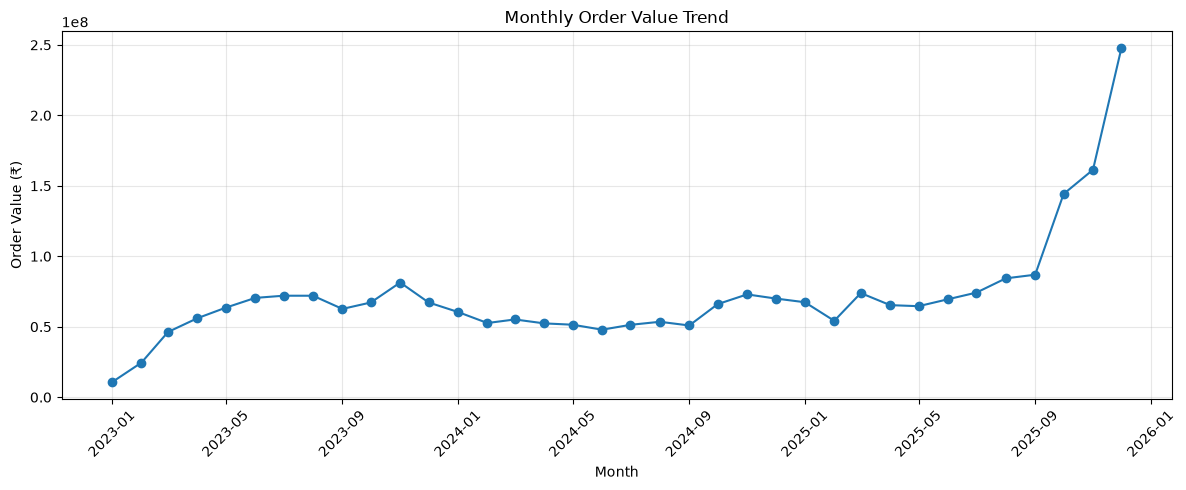

In [6]:

# Step 5: Sales performance analysis

# Convert numeric columns safely
for col in ["subtotal", "shipping_fee", "tax_amount", "final_amount"]:
    orders_clean[col] = pd.to_numeric(
        orders_clean[col], errors="coerce"
    )

# Overall sales metrics
print("SALES PERFORMANCE SUMMARY")
print("-" * 35)
print("Total orders:", f"{len(orders_clean):,}")
print("Unique customers ordering:", f"{orders_clean['customer_id'].nunique():,}")
print("Total order value (all statuses):",
      f"₹{orders_clean['final_amount'].sum():,.2f}")
print("Average order value:",
      f"₹{orders_clean['final_amount'].mean():,.2f}")
print("Median order value:",
      f"₹{orders_clean['final_amount'].median():,.2f}")

# Order status breakdown
print("\nORDER STATUS BREAKDOWN")
display(
    orders_clean["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Order Status")
    .reset_index(name="Order Count")
)

# Revenue by marketing channel
print("\nREVENUE BY MARKETING CHANNEL")
channel_revenue = (
    orders_clean.groupby("marketing_channel", dropna=False)
    .agg(
        order_count=("order_id", "count"),
        total_order_value=("final_amount", "sum")
    )
    .sort_values("total_order_value", ascending=False)
)
display(channel_revenue)

# Monthly order value trend
monthly_sales = (
    orders_clean.dropna(subset=["order_date"])
    .set_index("order_date")["final_amount"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Order Value (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


CATEGORY PERFORMANCE


,items_sold,total_revenue,total_cost,total_profit,profit_margin_pct
category,,,,,
Electronics,59068,1.223619e+09,1.215168e+09,8450905.95,0.69
Appliances,35842,4.052333e+08,3.894898e+08,15743436.40,3.89
Home & Kitchen,60205,1.580755e+08,1.296835e+08,28392024.89,17.96
Furniture,8118,1.470115e+08,1.326630e+08,14348527.85,9.76
Fashion,98750,1.393936e+08,9.320155e+07,46192014.22,33.14
Footwear,32501,8.260349e+07,5.830507e+07,24298429.50,29.42
Bags,29948,5.591211e+07,3.992772e+07,15984391.42,28.59
Health & Wellness,36095,3.182433e+07,2.486657e+07,6957754.85,21.86
Sports,13269,2.652405e+07,2.057873e+07,5945316.96,22.41


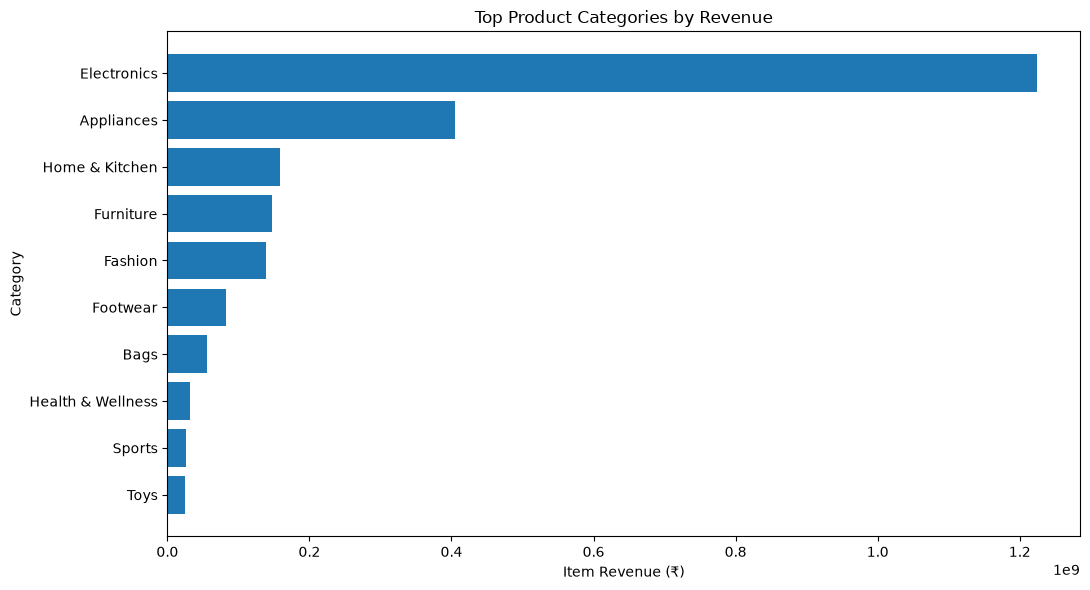

TOP 10 PRODUCTS BY PROFIT


,total_revenue,total_profit
product_name,,
Gandhi-Lanka Ultra Storage & Container,8.141222e+07,16809917.96
Setty Essential Formal Shoe,3.961464e+07,12709450.11
Chanda Deluxe Winter Wear,3.128365e+07,10159161.95
Shah Basic Handbag,3.020385e+07,8800852.32
"Chaudhry, Advanced Smartwatche",5.207029e+08,7972337.41
Ramakrishnan Advanced Winter Wear,2.076197e+07,7426234.68
Kar-Issac Premium Kids Wear,1.730784e+07,5437686.09
"Solanki, Basic Winter Wear",1.507040e+07,4763857.08
"Boase, Ultra Air Conditioner",6.394125e+07,4654790.80


In [7]:

# Step 6: Product and profit analysis

# Merge order items with product details
items_analysis = order_items_clean.merge(
    products_clean[
        ["product_id", "product_name", "category", "brand"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Profit and revenue by category
category_analysis = (
    items_analysis.groupby("category", dropna=False)
    .agg(
        items_sold=("quantity", "sum"),
        total_revenue=("item_revenue", "sum"),
        total_cost=("item_cost", "sum"),
        total_profit=("profit", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

category_analysis["profit_margin_pct"] = (
    category_analysis["total_profit"]
    / category_analysis["total_revenue"].replace(0, np.nan)
    * 100
)

print("CATEGORY PERFORMANCE")
display(category_analysis.round(2))

# Top 10 categories by revenue
top_categories = category_analysis.nlargest(10, "total_revenue")

plt.figure(figsize=(11, 6))
plt.barh(
    top_categories.index.astype(str)[::-1],
    top_categories["total_revenue"].values[::-1]
)
plt.title("Top Product Categories by Revenue")
plt.xlabel("Item Revenue (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Top 10 products by profit
top_products = (
    items_analysis.groupby("product_name", dropna=False)
    .agg(
        total_revenue=("item_revenue", "sum"),
        total_profit=("profit", "sum")
    )
    .sort_values("total_profit", ascending=False)
    .head(10)
)

print("TOP 10 PRODUCTS BY PROFIT")
display(top_products.round(2))


In [9]:

print("Shipment columns:")
print(shipments_clean.columns.tolist())

print("\nFirst 5 shipment records:")
display(shipments_clean.head())


Shipment columns:
['shipment_id', 'order_id', 'warehouse_city', 'delivery_city', 'shipping_method', 'dispatch_date', 'expected_delivery_date', 'actual_delivery_date', 'delivery_days', 'delivery_status', 'delayed_flag']

First 5 shipment records:


,shipment_id,order_id,warehouse_city,delivery_city,shipping_method,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_days,delivery_status,delayed_flag
0,SHIP1000000,ORD1000001,Chennai,Thiruvananthapuram,Economy/Surface,2023-02-11,2023-02-19,2023-02-17,6.0,Delivered,0
1,SHIP1000001,ORD1000002,Mumbai,Nagpur,Economy/Surface,2024-12-15,2024-12-23,2024-12-26,11.0,Delivered,1
2,SHIP1000002,ORD1000005,Chennai,Coimbatore,Standard,2025-01-09,2025-01-13,2025-01-12,3.0,Delivered,0
3,SHIP1000003,ORD1000006,Delhi-NCR (Gurugram),Noida,Same-Day,2025-05-26,2025-05-26,2025-05-27,1.0,Delivered,1
4,SHIP1000004,ORD1000007,Chennai,Thiruvananthapuram,Express,2025-10-04,2025-10-06,NaT,NaN,Cancelled in Transit,0


SHIPMENT STATUS BREAKDOWN


,Delivery Status,Shipment Count
0,Delivered,80679
1,Delivered then Returned,6681
2,Cancelled in Transit,2321



DELIVERY TIME SUMMARY


,Delivery Days
count,87360.00
mean,4.10
std,2.51
min,0.00
25%,2.00
50%,4.00
75%,6.00
max,14.00



DELIVERY BY SHIPPING METHOD


,shipment_count,average_delivery_days,delayed_shipments
shipping_method,,,
Same-Day,4440,0.83,2504
Next-Day,13460,1.81,1427
Express,18139,2.30,7023
Standard,40292,4.81,21519
Economy/Surface,13350,7.83,4975


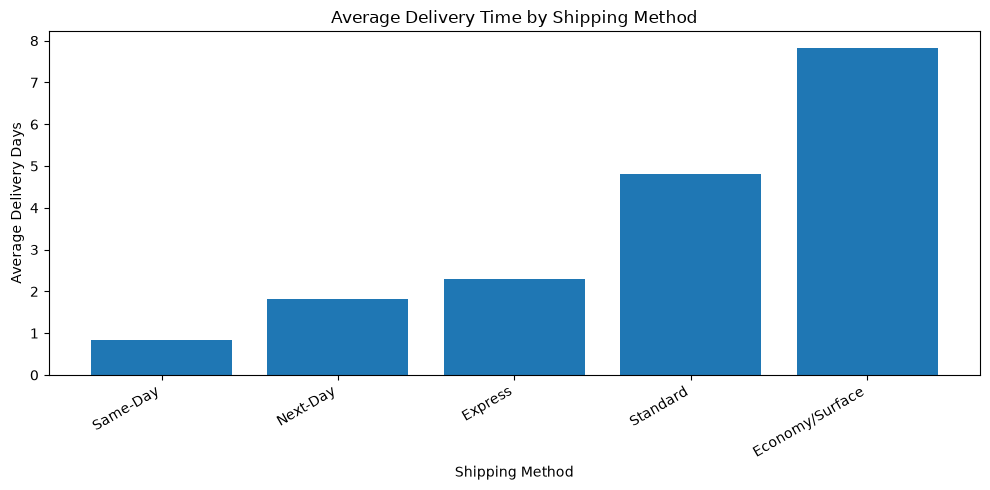


Overall delay rate: 41.76%


In [10]:

# Step 7: Delivery performance analysis

# Shipment status breakdown
print("SHIPMENT STATUS BREAKDOWN")
display(
    shipments_clean["delivery_status"]
    .value_counts(dropna=False)
    .rename_axis("Delivery Status")
    .reset_index(name="Shipment Count")
)

# Delivery time summary
shipments_clean["delivery_days"] = pd.to_numeric(
    shipments_clean["delivery_days"], errors="coerce"
)

print("\nDELIVERY TIME SUMMARY")
display(
    shipments_clean["delivery_days"]
    .describe()
    .to_frame("Delivery Days")
    .round(2)
)

# Average delivery time by shipping method
delivery_by_method = (
    shipments_clean.groupby("shipping_method", dropna=False)
    .agg(
        shipment_count=("shipment_id", "count"),
        average_delivery_days=("delivery_days", "mean"),
        delayed_shipments=("delayed_flag", "sum")
    )
    .sort_values("average_delivery_days")
)

print("\nDELIVERY BY SHIPPING METHOD")
display(delivery_by_method.round(2))

# Visualise average delivery time
plot_data = delivery_by_method.dropna(
    subset=["average_delivery_days"]
)

plt.figure(figsize=(10, 5))
plt.bar(
    plot_data.index.astype(str),
    plot_data["average_delivery_days"]
)
plt.title("Average Delivery Time by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Overall delay rate, excluding missing delay flags
delay_flags = pd.to_numeric(
    shipments_clean["delayed_flag"], errors="coerce"
).dropna()

print(
    "\nOverall delay rate:",
    f"{delay_flags.mean() * 100:.2f}%"
    if len(delay_flags) else "No valid delay data"
)


CUSTOMER SEGMENTS


,Customer Segment,Customer Count
0,Regular,11002
1,Budget,7713
2,New,3294
3,Premium,2991



LOYALTY TIERS


,Loyalty Tier,Customer Count
0,Bronze,13650
1,Silver,6810
2,Gold,3405
3,Platinum,1135



SPENDING BY CUSTOMER SEGMENT


,customer_count,average_total_spend,average_order_value,average_orders
customer_segment,,,,
Premium,2991,286622.67,29524.99,9.70
Regular,11002,110862.48,24559.76,4.43
Budget,7713,45355.25,19248.27,2.05
New,3294,22451.50,14088.14,1.05


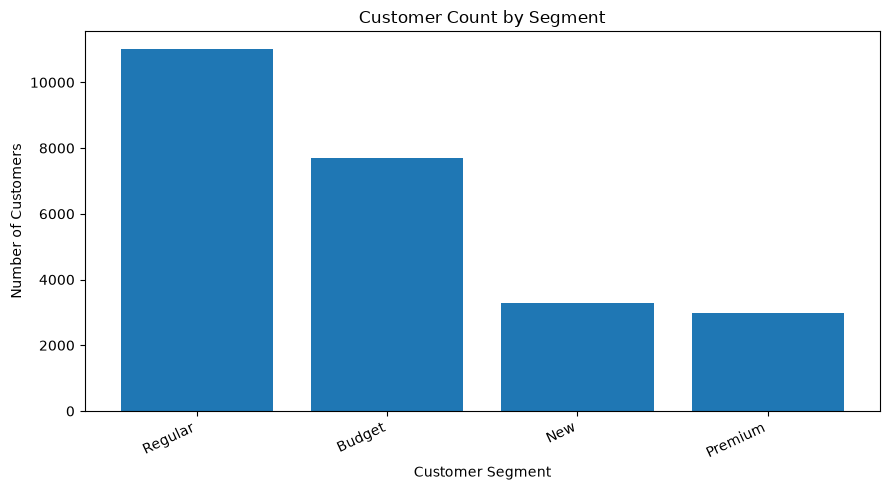

In [11]:

# Step 8: Customer analysis

# Customer segment breakdown
print("CUSTOMER SEGMENTS")
display(
    customers_clean["customer_segment"]
    .value_counts(dropna=False)
    .rename_axis("Customer Segment")
    .reset_index(name="Customer Count")
)

# Loyalty tier breakdown
print("\nLOYALTY TIERS")
display(
    customers_clean["loyalty_tier"]
    .value_counts(dropna=False)
    .rename_axis("Loyalty Tier")
    .reset_index(name="Customer Count")
)

# Average spending by customer segment
print("\nSPENDING BY CUSTOMER SEGMENT")
segment_spending = (
    customers_clean.groupby("customer_segment", dropna=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        average_total_spend=("total_spend", "mean"),
        average_order_value=("average_order_value", "mean"),
        average_orders=("total_orders", "mean")
    )
    .sort_values("average_total_spend", ascending=False)
)

display(segment_spending.round(2))

# Visualise customer segment sizes
segment_counts = customers_clean["customer_segment"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(segment_counts.index.astype(str), segment_counts.values)
plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


MARKETING CHANNEL PERFORMANCE


,order_count,total_order_value,average_order_value,unique_customers
marketing_channel,,,,
Organic Search,22842,5.878331e+08,25734.75,8552
Direct/App,13746,3.530567e+08,25684.33,5075
Paid Search,13348,3.398562e+08,25461.21,5724
Social Media - Instagram,10863,2.841236e+08,26155.17,5079
Email Marketing,8492,2.192734e+08,25821.18,3439
Social Media - Facebook,8065,2.049813e+08,25416.16,3854
Referral,6818,1.737897e+08,25489.83,2722
Affiliate,6437,1.679082e+08,26084.85,3004
Influencer Marketing,5775,1.480107e+08,25629.55,2680


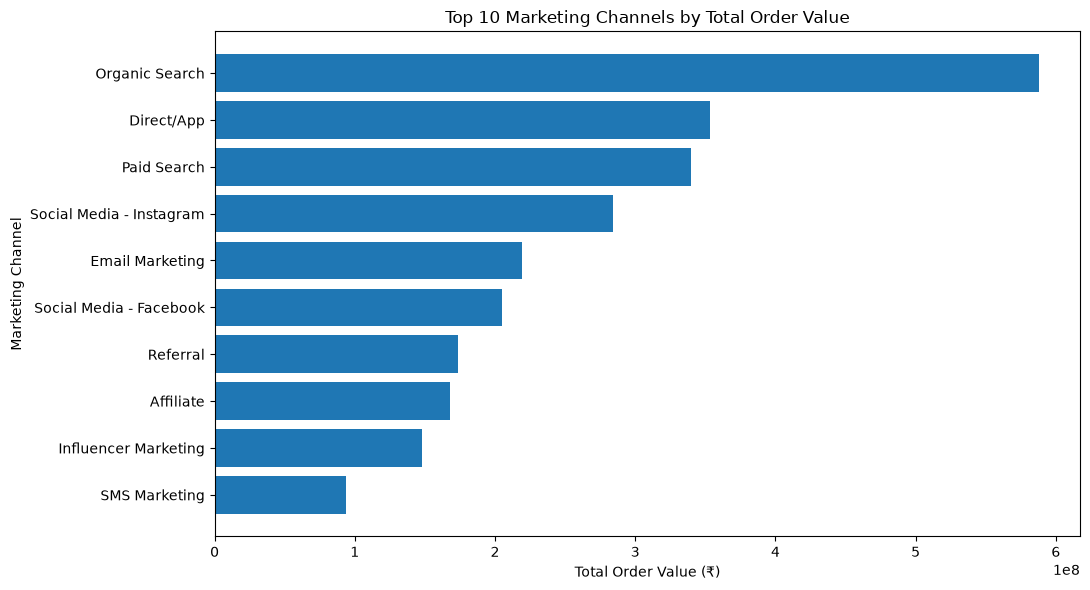


CUSTOMER ACQUISITION CHANNELS


,Acquisition Channel,Customer Count
0,Organic Search,5505
1,Paid Search,3473
2,Direct/App,3022
3,Social Media - Instagram,3013
4,Social Media - Facebook,2179
5,Email Marketing,2014
6,Affiliate,1743
7,Referral,1534
8,Influencer Marketing,1499
9,SMS Marketing,1018


In [12]:

# Step 9: Marketing channel performance

# Orders and order value by marketing channel
marketing_analysis = (
    orders_clean.groupby("marketing_channel", dropna=False)
    .agg(
        order_count=("order_id", "count"),
        total_order_value=("final_amount", "sum"),
        average_order_value=("final_amount", "mean"),
        unique_customers=("customer_id", "nunique")
    )
    .sort_values("total_order_value", ascending=False)
)

print("MARKETING CHANNEL PERFORMANCE")
display(marketing_analysis.round(2))

# Top channels by order value
plot_data = marketing_analysis.head(10).sort_values(
    "total_order_value"
)

plt.figure(figsize=(11, 6))
plt.barh(
    plot_data.index.astype(str),
    plot_data["total_order_value"]
)
plt.title("Top 10 Marketing Channels by Total Order Value")
plt.xlabel("Total Order Value (₹)")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()

# Customer acquisition channels
print("\nCUSTOMER ACQUISITION CHANNELS")
display(
    customers_clean["acquisition_channel"]
    .value_counts(dropna=False)
    .rename_axis("Acquisition Channel")
    .reset_index(name="Customer Count")
)


ORDER PERFORMANCE BY DISCOUNT


,order_count,average_order_value,total_order_value
discount_percentage,,,
0.0,31192,29033.48,9.056122e+08
5.0,11083,27459.78,3.043367e+08
10.0,11944,26841.43,3.205940e+08
15.0,11784,25099.50,2.957725e+08
20.0,11715,23769.72,2.784623e+08
25.0,11190,21913.95,2.452171e+08
30.0,11092,20068.29,2.225975e+08


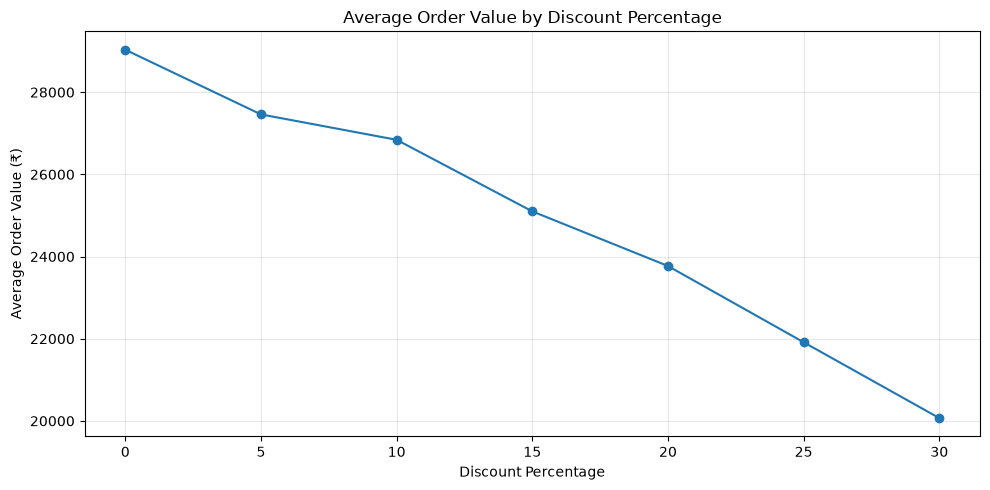


Discount data quality:
Missing discount values: 0
Minimum discount: 0.0
Maximum discount: 30.0


In [13]:

# Step 10: Discount analysis

# Summarise orders by discount percentage
discount_analysis = (
    orders_clean.groupby("discount_percentage", dropna=False)
    .agg(
        order_count=("order_id", "count"),
        average_order_value=("final_amount", "mean"),
        total_order_value=("final_amount", "sum")
    )
    .sort_index()
)

print("ORDER PERFORMANCE BY DISCOUNT")
display(discount_analysis.round(2))

# Visualise average order value by discount
plot_data = discount_analysis.dropna(
    subset=["average_order_value"]
).sort_index()

plt.figure(figsize=(10, 5))
plt.plot(
    plot_data.index,
    plot_data["average_order_value"],
    marker="o"
)
plt.title("Average Order Value by Discount Percentage")
plt.xlabel("Discount Percentage")
plt.ylabel("Average Order Value (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Check discount range and missing values
print("\nDiscount data quality:")
print("Missing discount values:", orders_clean["discount_percentage"].isna().sum())
print("Minimum discount:", orders_clean["discount_percentage"].min())
print("Maximum discount:", orders_clean["discount_percentage"].max())


In [14]:

# Step 11: Consolidated business findings

print("=" * 55)
print("E-COMMERCE CAPSTONE: KEY FINDINGS")
print("=" * 55)

# 1. Order overview
print("\n1. ORDER OVERVIEW")
print(f"Orders analysed: {len(orders_clean):,}")
print(f"Unique customers placing orders: {orders_clean['customer_id'].nunique():,}")

# 2. Customer segments
print("\n2. CUSTOMER SEGMENTS")
print(customers_clean["customer_segment"].value_counts().to_string())

# 3. Premium customers
premium = customers_clean[
    customers_clean["customer_segment"] == "Premium"
]
print(f"\nPremium customers: {len(premium):,}")
print(f"Premium average total spend: ₹{premium['total_spend'].mean():,.2f}")

# 4. Delivery performance
print("\n4. DELIVERY PERFORMANCE")
print(f"Average delivery time: {shipments_clean['delivery_days'].mean():.2f} days")
print("\nAverage delivery time by shipping method:")
print(
    shipments_clean.groupby("shipping_method")["delivery_days"]
    .mean().sort_values().round(2).to_string()
)

# 5. Product category performance
print("\n5. TOP PRODUCT CATEGORIES BY PROFIT")
print(
    category_analysis[["total_revenue", "total_profit"]]
    .sort_values("total_profit", ascending=False)
    .head(5).round(2).to_string()
)

print("\n6. TOP MARKETING CHANNELS BY ORDER VALUE")
print(
    marketing_analysis[["order_count", "total_order_value"]]
    .head(5).round(2).to_string()
)

print("\nFindings summary generated.")


E-COMMERCE CAPSTONE: KEY FINDINGS

1. ORDER OVERVIEW
Orders analysed: 100,000
Unique customers placing orders: 22,820

2. CUSTOMER SEGMENTS
customer_segment
Regular    11002
Budget      7713
New         3294
Premium     2991

Premium customers: 2,991
Premium average total spend: ₹286,622.67

4. DELIVERY PERFORMANCE
Average delivery time: 4.10 days

Average delivery time by shipping method:
shipping_method
Same-Day           0.83
Next-Day           1.81
Express            2.30
Standard           4.81
Economy/Surface    7.83

5. TOP PRODUCT CATEGORIES BY PROFIT
                total_revenue  total_profit
category                                   
Fashion          1.393936e+08   46192014.22
Home & Kitchen   1.580755e+08   28392024.89
Footwear         8.260349e+07   24298429.50
Bags             5.591211e+07   15984391.42
Appliances       4.052333e+08   15743436.40

6. TOP MARKETING CHANNELS BY ORDER VALUE
                          order_count  total_order_value
marketing_channel          

In [15]:

# Step 12: Create a folder for report visuals

from pathlib import Path

OUTPUT_DIR = Path("Week4/Day-5/outputs")

# Support running from inside the Day-5 folder too
if not OUTPUT_DIR.parent.exists():
    OUTPUT_DIR = Path("outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the currently created analysis tables
category_analysis.to_csv(OUTPUT_DIR / "category_analysis.csv")
marketing_analysis.to_csv(OUTPUT_DIR / "marketing_analysis.csv")
delivery_by_method.to_csv(OUTPUT_DIR / "delivery_by_method.csv")
segment_spending.to_csv(OUTPUT_DIR / "customer_segment_analysis.csv")
discount_analysis.to_csv(OUTPUT_DIR / "discount_analysis.csv")

print("Analysis tables saved to:", OUTPUT_DIR.resolve())
print("Saved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)


Analysis tables saved to: D:\Cynaris\cynaris-internship-vamshika\Week4\Day-5\outputs
Saved files:
- category_analysis.csv
- customer_segment_analysis.csv
- delivery_by_method.csv
- discount_analysis.csv
- marketing_analysis.csv


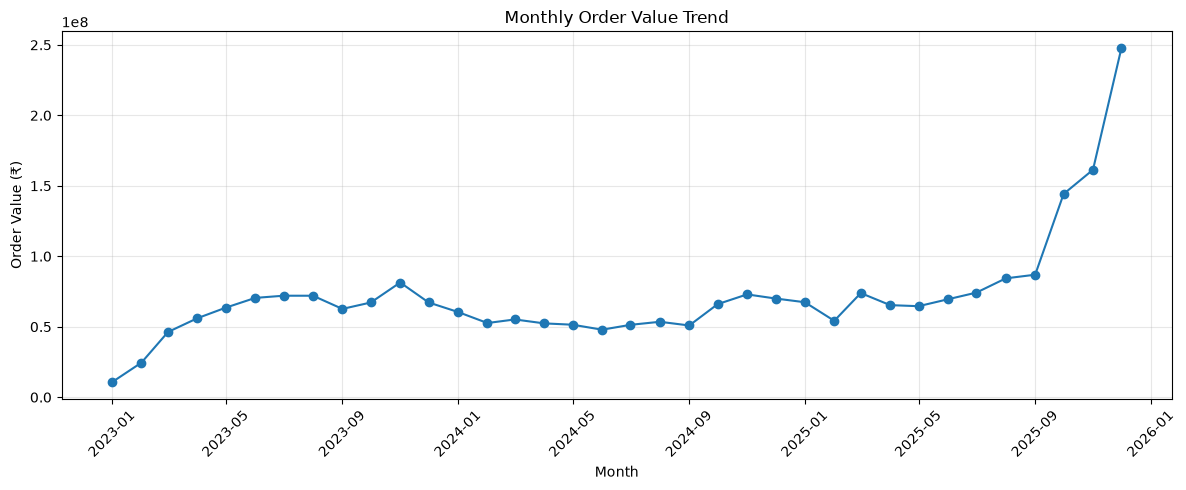

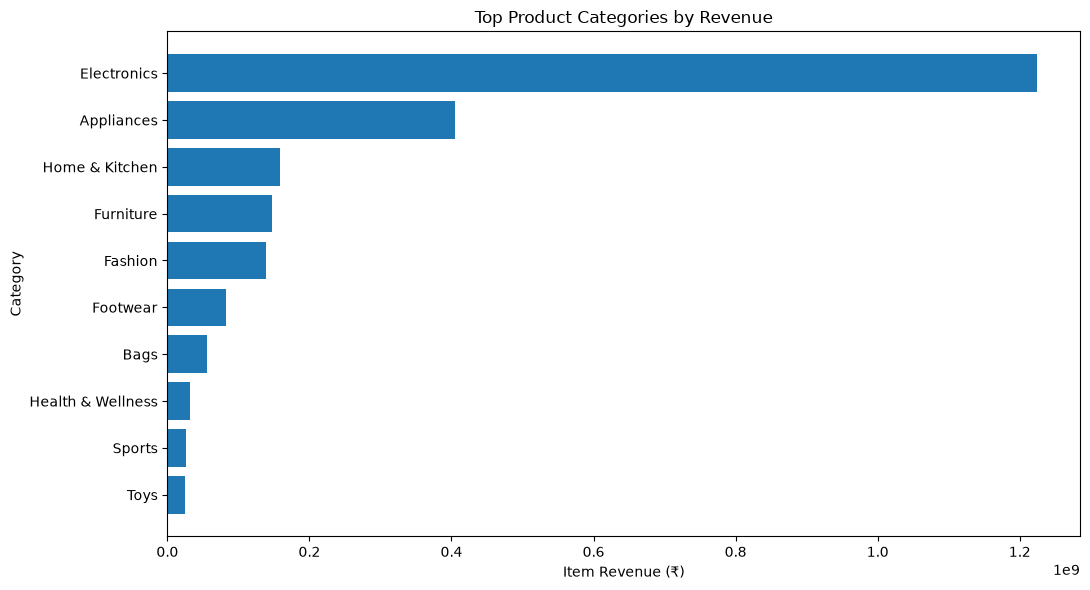

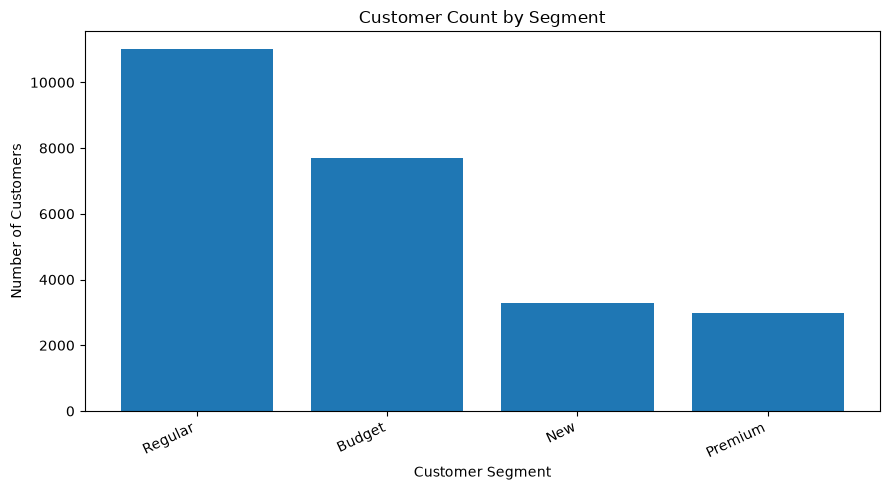

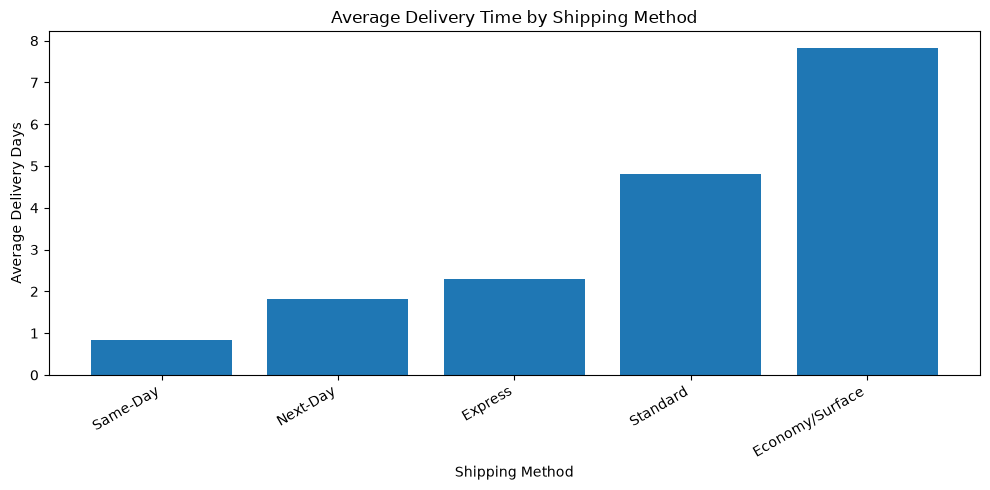

In [17]:

# Step 13: Save analysis charts as PNG files

# 1. Monthly order value trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Order Value (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_order_value.png", dpi=150)
plt.show()

# 2. Product category revenue
plt.figure(figsize=(11, 6))
plt.barh(
    top_categories.index.astype(str)[::-1],
    top_categories["total_revenue"].values[::-1]
)
plt.title("Top Product Categories by Revenue")
plt.xlabel("Item Revenue (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "category_revenue.png", dpi=150)
plt.show()

# 3. Customer segment counts
segment_counts = customers_clean["customer_segment"].value_counts()
plt.figure(figsize=(9, 5))
plt.bar(segment_counts.index.astype(str), segment_counts.values)
plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "customer_segments.png", dpi=150)
plt.show()

# 4. Average delivery time by shipping method
delivery_plot_data = delivery_by_method.dropna(
    subset=["average_delivery_days"]
)

plt.figure(figsize=(10, 5))
plt.bar(
    delivery_plot_data.index.astype(str),
    delivery_plot_data["average_delivery_days"]
)
plt.title("Average Delivery Time by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "delivery_performance.png", dpi=150)
plt.show()
